In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display


In [10]:
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "processed" / "btc_spy_daily.csv").exists()
)
PROCESSED_DIR = project_root / "data" / "processed"
RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TRADING_DAYS_PER_YEAR = 252
ROLLING_WINDOW = 63  # Approximately three trading months


In [11]:
prices = pd.read_csv(
    PROCESSED_DIR / "btc_spy_daily.csv", index_col="date", parse_dates=True
).rename(columns={"price_btc": "BTC", "price_spy": "SPY"})[["BTC", "SPY"]]

assert prices.index.is_monotonic_increasing, "Prices must be sorted by date."
assert prices.index.is_unique, "Duplicate dates found."
assert np.isfinite(prices.to_numpy()).all(), "Prices contain missing or infinite values."
assert prices.gt(0).all().all(), "Prices must be positive."
assert len(prices) > ROLLING_WINDOW, "Not enough prices for the rolling window."

returns = prices.pct_change(fill_method=None).iloc[1:]
period_label = f"{prices.index[0]:%Y-%m-%d} to {prices.index[-1]:%Y-%m-%d}"
print(f"Price period: {period_label}")
print(f"Return observations: {len(returns):,}")
display(returns.head().style.format("{:.2%}"))


Price period: 2013-12-27 to 2026-11-12
Return observations: 3,238


,BTC,SPY
date,,
2013-12-30 00:00:00,2.87%,-0.02%
2013-12-31 00:00:00,-0.28%,0.47%
2014-01-02 00:00:00,6.42%,-0.96%
2014-01-03 00:00:00,2.04%,-0.02%
2014-01-06 00:00:00,16.44%,-0.29%


In [12]:
interval_volatility = returns.std(ddof=1)
annualized_volatility = interval_volatility * np.sqrt(TRADING_DAYS_PER_YEAR)

volatility_summary = pd.DataFrame({
    "Shared-interval volatility": interval_volatility,
    "Annualized volatility": annualized_volatility,
})
volatility_summary.index.name = "Asset"
display(volatility_summary.style.format("{:.2%}").set_caption(period_label))

volatility_ratio = annualized_volatility["BTC"] / annualized_volatility["SPY"]
print(f"BTC's estimated annualized volatility is {volatility_ratio:.2f} times SPY's.")


,Shared-interval volatility,Annualized volatility
Asset,,
BTC,4.17%,66.25%
SPY,1.08%,17.13%


BTC's estimated annualized volatility is 3.87 times SPY's.


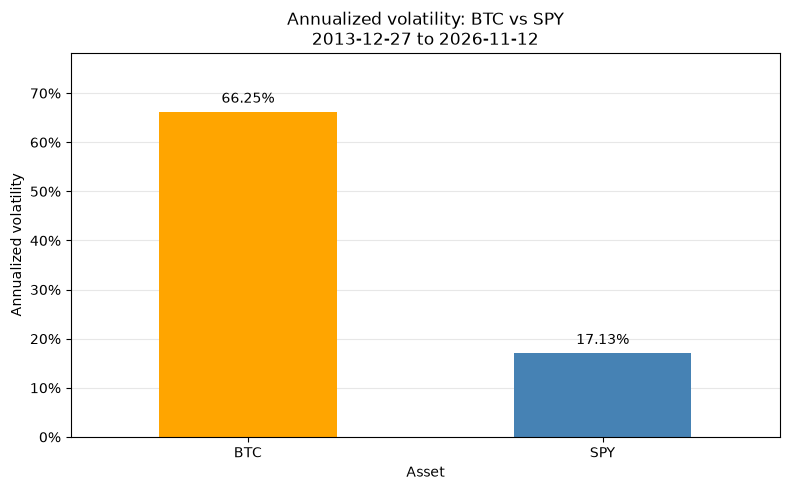

In [13]:
ax = annualized_volatility.plot.bar(
    figsize=(8, 5), color=["orange", "steelblue"], rot=0
)
ax.set_title(f"Annualized volatility: BTC vs SPY\n{period_label}")
ax.set_xlabel("Asset")
ax.set_ylabel("Annualized volatility")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.bar_label(ax.containers[0], labels=[f"{v:.2%}" for v in annualized_volatility], padding=4)
ax.margins(y=0.18)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "annualized_volatility.png", dpi=300)
plt.show()


In [14]:
rolling_volatility = (
    returns.rolling(window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std(ddof=1)
    * np.sqrt(TRADING_DAYS_PER_YEAR)
)
rolling_available = rolling_volatility.dropna(how="all")
display(rolling_available.tail().style.format("{:.2%}"))


,BTC,SPY
date,,
2026-11-06 00:00:00,40.35%,13.59%
2026-11-09 00:00:00,40.35%,14.43%
2026-11-10 00:00:00,40.62%,14.43%
2026-11-11 00:00:00,40.62%,14.61%
2026-11-12 00:00:00,40.60%,14.61%


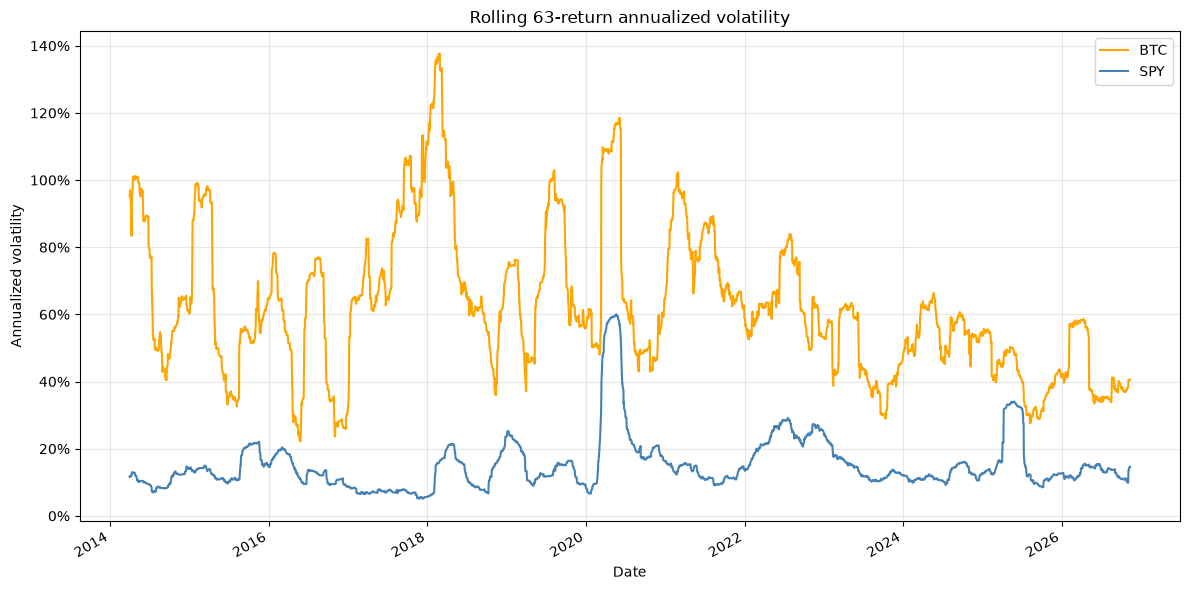

In [15]:
ax = rolling_available.plot(figsize=(12, 6), color=["orange", "steelblue"])
ax.set_title(f"Rolling {ROLLING_WINDOW}-return annualized volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=0.3)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "rolling_volatility.png", dpi=300)
plt.show()


In [16]:
volatility_summary.to_csv(RESULTS_DIR / "volatility_summary.csv")
rolling_available.to_csv(RESULTS_DIR / "rolling_annualized_volatility.csv", index_label="date")

report = (
    '<!doctype html><html><head><meta charset="utf-8"><title>BTC vs SPY volatility</title>'
    '<style>body{font-family:system-ui;max-width:950px;margin:40px auto;padding:0 20px;}'
    'th,td{padding:10px;text-align:right;border-bottom:1px solid #ddd;}'
    'img{max-width:100%;}table{border-collapse:collapse;}</style></head><body>'
    '<h1>BTC vs SPY: volatility</h1>'
    f'<p>{period_label} | {len(returns):,} shared-interval returns</p>'
    + volatility_summary.style.format("{:.2%}").to_html()
    + f'<p>BTC / SPY volatility ratio: {volatility_ratio:.2f}.</p>'
    '<p>Sample standard deviation of simple returns, annualized by sqrt(252). '
    'BTC weekend movements are included in the next shared-date return. '
    'Source closing timestamps may differ. Volatility measures both upward and downward fluctuations.</p>'
    f'<p>Rolling window: {ROLLING_WINDOW} return observations. '
    'Annualization is an approximation; historical volatility is not a forecast.</p>'
    '<img src="annualized_volatility.png" alt="Full-period annualized volatility">'
    '<img src="rolling_volatility.png" alt="Rolling annualized volatility">'
    '</body></html>'
)
report_path = RESULTS_DIR / "volatility_report.html"
report_path.write_text(report, encoding="utf-8")
print(f"Saved two CSVs, two charts, and {report_path.name} in {RESULTS_DIR}")


Saved two CSVs, two charts, and volatility_report.html in /Users/nikolaskefalonitis/Desktop/All_folders/projects/quant/btcVSsp500/results
